# Ethiopia Economic Indicators

This notebook loads World Bank data for Ethiopia, cleans it, analyzes it with NumPy,
and reports the findings. All logic lives in `src/econ_pipeline/` (load, clean,
process, report); this notebook only calls it.

## Questions
1. In which years did Ethiopia's inflation exceed 20%, and in how many years did that happen?
2. What was the average annual percentage change in the official exchange rate (mean and median), and in which year was the single largest jump?
3. Is there a relationship between inflation and GDP growth? Is average growth lower in high-inflation years than in the other years?

## How to run
Run all cells from top to bottom. The same notebook works in Jupyter and in Colab.

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

REPO_NAME = "ethiopia-economic-indicators"
REPO_URL = f"https://github.com/YibeltalMarie/{REPO_NAME}.git"

# 1. Opened from the notebooks/ folder (local Jupyter)? Move up to the project root.
if not Path("src/econ_pipeline").exists() and Path("../src/econ_pipeline").exists():
    os.chdir("..")

# 2. Opened on its own in Colab? Get the project code first.
if not Path("src/econ_pipeline").exists() and "google.colab" in sys.modules:
    if not Path(REPO_NAME).exists():
        subprocess.run(["git", "clone", REPO_URL], check=True)
    os.chdir(REPO_NAME)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True
    )

sys.path.insert(0, "src")
print("Working directory:", Path.cwd())

Working directory: /content/ethiopia-economic-indicators


## 1. Load the raw data
Raw files are downloaded once and never edited. If they already exist, nothing is
downloaded again. The manifest records where and when each file came from.

In [2]:
from econ_pipeline.load import INDICATORS, download_indicator

for name, code in INDICATORS.items():
    path = download_indicator(code, "data/raw")
    print(f"{name:15} {path}")

manifest = json.loads(Path("data/raw/MANIFEST.json").read_text())
print()
for code, info in manifest.items():
    print(f"{code:20} downloaded {info['downloaded_at_utc']}")

inflation       data/raw/FP.CPI.TOTL.ZG.csv
exchange_rate   data/raw/PA.NUS.FCRF.csv
gdp_growth      data/raw/NY.GDP.MKTP.KD.ZG.csv

FP.CPI.TOTL.ZG       downloaded 2026-10-20T08:31:39+00:00
PA.NUS.FCRF          downloaded 2026-10-20T08:31:39+00:00
NY.GDP.MKTP.KD.ZG    downloaded 2026-10-20T08:31:39+00:00


## 2. Clean the data
Each cleaning rule is a small tested function (see `docs/data_quality_notes.md`).
Missing years are dropped, never filled.

In [3]:
from econ_pipeline.clean import build_dataset, save_dataset

dataset = build_dataset()
save_dataset(dataset, "data/processed/ethiopia_indicators.csv")

print("shape (years, columns):", dataset.shape)
print()
print("missing values per column:")
print(dataset.isna().sum())
dataset.head()

shape (years, columns): (66, 4)

missing values per column:
year             0
inflation        6
exchange_rate    1
gdp_growth       2
dtype: int64


,year,inflation,exchange_rate,gdp_growth
0,1960,NaN,2.48447,NaN
1,1961,NaN,2.48447,NaN
2,1962,NaN,2.48447,4.326091
3,1963,NaN,2.48447,4.518634
4,1964,NaN,2.50000,4.090486


## 3. Process with NumPy
One call answers all three questions. Every number below comes from this result.

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

from econ_pipeline.process import answer_questions
from econ_pipeline.report import (
    plot_exchange_rate,
    plot_inflation,
    plot_inflation_vs_growth,
    summary_table,
)

answers = answer_questions(dataset)
table = summary_table(answers)

## Q1. Which years had inflation above 20%?

10 years: 1976, 1991, 2008, 2011, 2012, 2020, 2021, 2022, 2023, 2024.


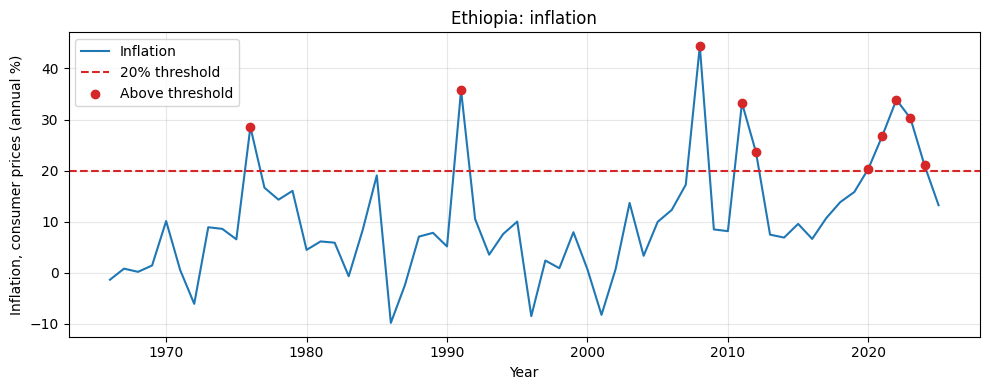

In [5]:
print(table.loc[0, "finding"])
fig = plot_inflation(dataset)
plt.show()

## Q2. How much did the official exchange rate change each year?
The rate was fixed for long stretches, so many yearly changes are zero. That is why
the median is reported next to the mean.

Across 64 year-over-year changes, the mean was 6.3% and the median was 0.37%. The rate did not change in 23 of those years. The largest jump was 78.4% in 1993.


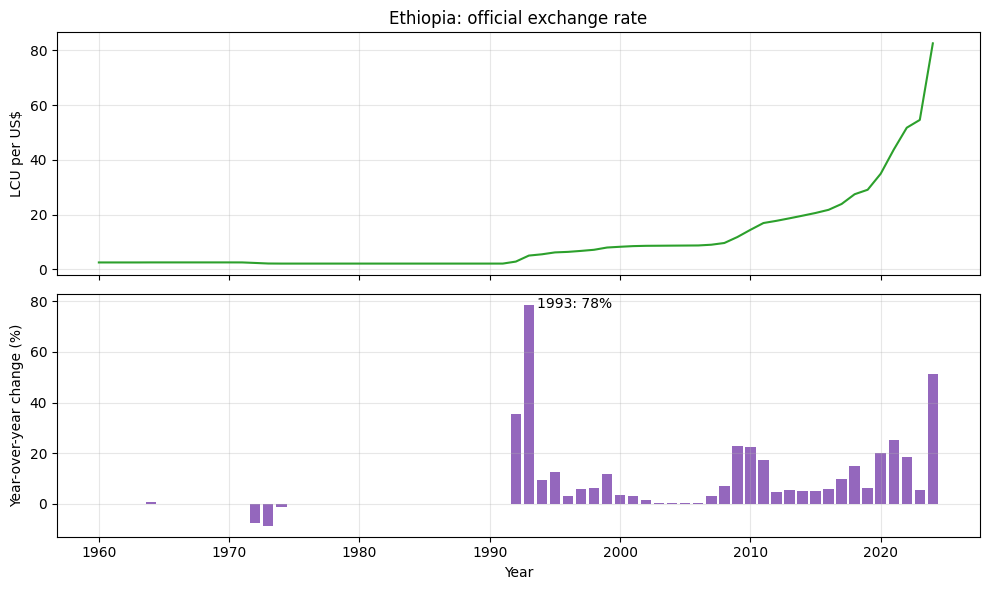

In [6]:
print(table.loc[1, "finding"])
fig = plot_exchange_rate(dataset)
plt.show()

## Q3. Is there a relationship between inflation and GDP growth?

The correlation is -0.13 (weak negative). Mean growth was 5.49% in the 10 years above the threshold and 5.33% in the other 50 years, which is higher in high-inflation years. This describes a linear pattern in these years only; it does not show cause, and 10 high-inflation years is a small sample.


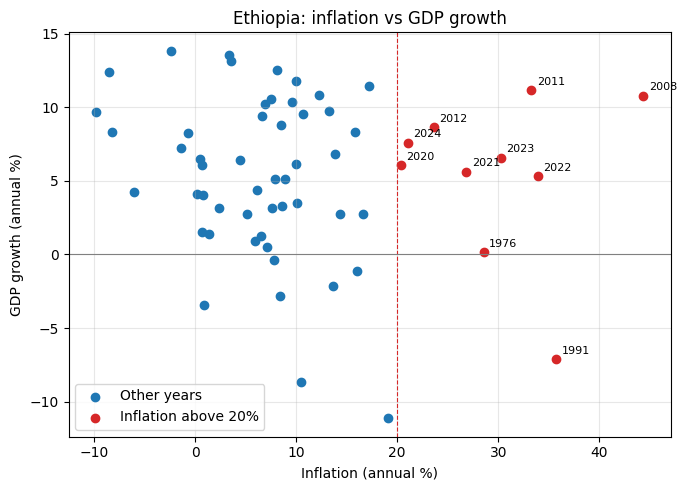

In [7]:
print(table.loc[2, "finding"])
fig = plot_inflation_vs_growth(dataset)
plt.show()

## Summary

In [8]:
pd.set_option("display.max_colwidth", None)
table

,question,finding
0,Q1. In which years was inflation above 20%?,"10 years: 1976, 1991, 2008, 2011, 2012, 2020, 2021, 2022, 2023, 2024."
1,Q2. How much did the official exchange rate change each year?,"Across 64 year-over-year changes, the mean was 6.3% and the median was 0.37%. The rate did not change in 23 of those years. The largest jump was 78.4% in 1993."
2,Q3. Is there a relationship between inflation and GDP growth?,"The correlation is -0.13 (weak negative). Mean growth was 5.49% in the 10 years above the threshold and 5.33% in the other 50 years, which is higher in high-inflation years. This describes a linear pattern in these years only; it does not show cause, and 10 high-inflation years is a small sample."


## Limitations
- The data comes from the World Bank. Recent values can be revised in later releases,
  so results may change slightly when the raw files are downloaded again.
- Correlation describes a linear pattern in these years. It does not show cause, and a
  small number of unusual years can change it a lot.
- The exchange rate has fixed-rate and moving-rate periods that behave very differently.
  A single average blends them, which is why the median and the largest jump are
  reported too.
- Only Ethiopia and three indicators are covered in this version.